In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.stats import gaussian_sigma_to_fwhm
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.integrate import trapezoid
from scipy.constants import c

CATALOG = Path("clagn_130_candidates_full_data.csv")
SPECTRA_ROOT = Path.cwd()
OUT = Path("batch_line_results")
LINES = ("Halpha", "Hbeta", "MgII", "CIV")
MAX_SPECTRA = None
C_KMS = c / 1000
OUT.mkdir(exist_ok=True)


REGIONS = {
    "Halpha": (6564.61, (6380, 6690), ((6210, 6250), (6810, 6870))),
    "Hbeta":  (4862.68, (4730, 5075), ((4500, 4560), (5100, 5160))),
    "MgII":   (2799.11, (2685, 2925), ((2610, 2650), (3010, 3050))),
    "CIV":    (1549.48, (1490, 1620), ((1445, 1470), (1675, 1700))),
}


MASKS = {
    "Halpha": [(6549.86, 10), (6564.61, 10), (6585.27, 10)],
    "Hbeta": [(4862.68, 9), (4960.30, 12), (5008.24, 12)],
    "MgII": [],
    "CIV": [],
}

catalog = pd.read_csv(CATALOG, dtype={"gaia_source_id": "string"}, low_memory=False)
catalog = catalog.drop_duplicates(["gaia_source_id", "local_path"]).copy()
catalog["z"] = pd.to_numeric(catalog["z"], errors="coerce")
catalog["z_ref"] = catalog.gaia_source_id.map(
    catalog.groupby("gaia_source_id")["z"].median()
)
print(f"{catalog.gaia_source_id.nunique()} objects, {len(catalog)} spectra")

130 objects, 542 spectra


In [2]:
def read_spec(path, z):
    with fits.open(path) as hdul:
        d = hdul["COADD"].data
        wave = 10.0**d["loglam"] / (1 + z)
        flux = np.asarray(d["flux"], float) * (1 + z)
        ivar = np.asarray(d["ivar"], float) / (1 + z)**2
        mask = d["and_mask"] if "and_mask" in d.names else np.zeros(len(wave))
    good = (ivar > 0) & np.isfinite(ivar) & np.isfinite(flux) & (mask == 0)
    return wave, flux, ivar, good


def broad_gaussian(w, area, mu, sigma_wave):
    return area * norm.pdf(w, loc=mu, scale=sigma_wave)


def fit_line(spec, line, details=False):
    w, f, iv, good = spec
    center, region, sides = REGIONS[line]
    result = {"line": line, "status": "outside_coverage", "fit_quality": "unavailable"}

    if w.min() > min(region[0], *[a for a, b in sides]) or w.max() < max(region[1], *[b for a, b in sides]):
        result["status"] = "partial_window"
        return result

    region_pixels = (w >= region[0]) & (w <= region[1]) & good
    side = good & (((w >= sides[0][0]) & (w <= sides[0][1])) |
                   ((w >= sides[1][0]) & (w <= sides[1][1])))
    use = region_pixels.copy()
    for wavelength, half_width in MASKS[line]:
        use &= np.abs(w - wavelength) > half_width

    if use.sum() < 25 or side.sum() < 12:
        result["status"] = "poor_data"
        return result

    coeff = np.polyfit((w[side] - center)/1000, f[side], 1, w=np.sqrt(iv[side]))
    x, y, err = w[use], f[use], 1/np.sqrt(iv[use])
    sub = y - np.polyval(coeff, (x-center)/1000)

    area0 = max(trapezoid(np.maximum(sub, 0), x), 1.0)
    max_velocity = 4000 if line in ("MgII", "CIV") else 2500
    min_sigma = 425*center/C_KMS
    max_sigma = 6000*center/C_KMS
    p0 = [area0, center, 1400*center/C_KMS]
    bounds = ([0, center*(1-max_velocity/C_KMS), min_sigma],
              [np.inf, center*(1+max_velocity/C_KMS), max_sigma])

    try:
        p, cov = curve_fit(broad_gaussian, x, sub, p0=p0,
                           bounds=bounds, sigma=err, absolute_sigma=True,
                           maxfev=4000)
    except (ValueError, RuntimeError):
        result["status"] = "fit_failed"
        return result

    area, mu, sigma_wave = p
    formal_err = np.sqrt(cov[0, 0]) if np.isfinite(cov[0, 0]) and cov[0, 0] >= 0 else np.nan
    snr = area/formal_err if formal_err > 0 else np.nan
    width_kms = sigma_wave/mu * C_KMS
    chi2 = np.sum(((sub - broad_gaussian(x, *p))/err)**2)/max(len(x)-3, 1)
    width_at_bound = width_kms < 450 or width_kms > 5900
    quality = ("weak_component" if not (snr >= 3) else
               "review_needed" if chi2 > 3 or width_at_bound else "usable")
    result.update({"status": "fitted", "fit_quality": quality,
                   "line_flux_1e-17": area, "flux_err_formal_1e-17": formal_err,
                   "formal_snr": snr, "center_A": mu,
                   "fwhm_km_s": width_kms*gaussian_sigma_to_fwhm,
                   "rest_ew_A": area/np.polyval(coeff, 0) if np.polyval(coeff, 0) > 0 else np.nan,
                   "line_reduced_chi2": chi2, "width_at_bound": width_at_bound})
    if details:
        xx = w[region_pixels]
        yy = f[region_pixels] - np.polyval(coeff, (xx-center)/1000)
        kept = np.ones(len(xx), bool)
        for wavelength, half_width in MASKS[line]:
            kept &= np.abs(xx-wavelength) > half_width
        result["_plot"] = (xx, yy, kept, broad_gaussian(xx, *p))
    return result

In [3]:
rows = []
subset = catalog.head(MAX_SPECTRA) if MAX_SPECTRA is not None else catalog
for i, row in enumerate(subset.itertuples(index=False), 1):
    info = {"gaia_source_id": str(row.gaia_source_id), "mjd": row.mjd,
            "z_ref": row.z_ref, "local_path": row.local_path}
    path = SPECTRA_ROOT / row.local_path
    if path.is_file() and np.isfinite(row.z_ref):
        spec = read_spec(path, row.z_ref)
        for line in LINES:
            rows.append({**info, **fit_line(spec, line)})
    else:
        for line in LINES:
            rows.append({**info, "line": line, "status": "missing_file_or_redshift",
                         "fit_quality": "unavailable"})
    if i % 100 == 0:
        print(f"{i}/{len(subset)} spectra")

measurements = pd.DataFrame(rows)
measurements.to_csv(OUT / "line_measurements_full.csv", index=False)
print(pd.crosstab(measurements.line, measurements.fit_quality))
print("Saved:", OUT / "line_measurements_full.csv")

100/542 spectra
200/542 spectra
300/542 spectra
400/542 spectra
500/542 spectra
fit_quality  review_needed  unavailable  usable  weak_component
line                                                           
CIV                     18          398     126               0
Halpha                  72          387      83               0
Hbeta                   93          187     261               1
MgII                    29          172     340               1
Saved: batch_line_results/line_measurements_full.csv


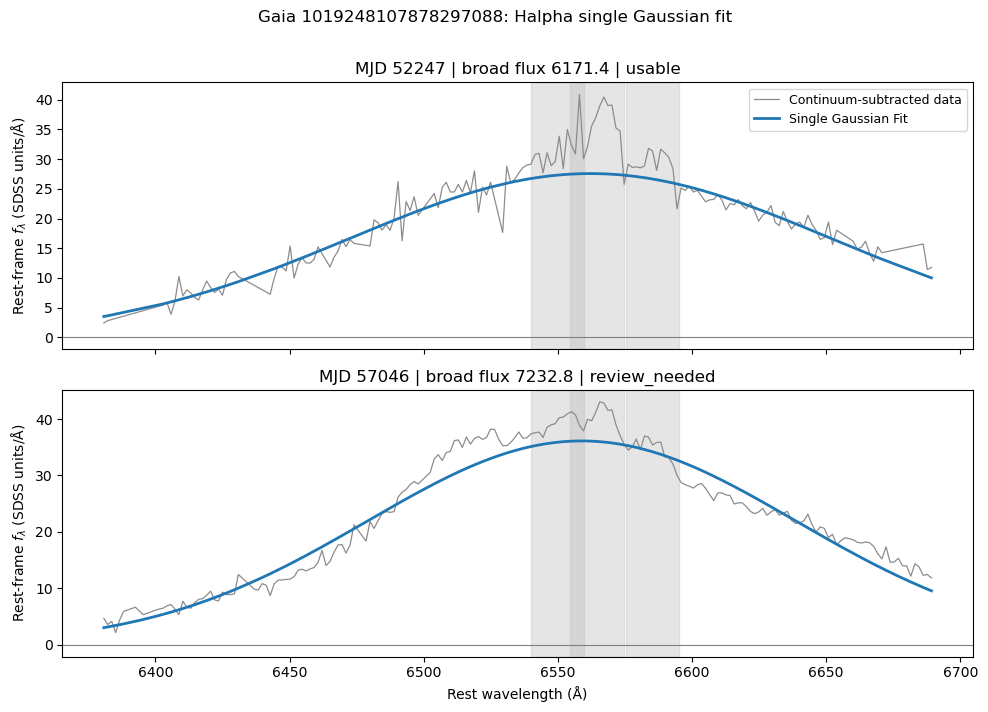

In [4]:
def plot_object(gaia_id, line="Halpha", mjds=None):
    group = catalog[catalog.gaia_source_id.eq(str(gaia_id))].sort_values("mjd")
    if mjds is not None:
        group = group[group.mjd.isin(mjds)]
    elif len(group) > 2:
        group = group.iloc[[0, -1]]

    fig, axes = plt.subplots(len(group), 1, figsize=(10, 3.5*len(group)),
                             sharex=True, squeeze=False)
    for ax, row in zip(axes.ravel(), group.itertuples(index=False)):
        result = fit_line(read_spec(SPECTRA_ROOT / row.local_path, row.z_ref),
                          line, details=True)
        if result["status"] != "fitted":
            ax.set_title(f"MJD {row.mjd}: {result['status']}")
            continue
        x, sub, keep, model = result["_plot"]
        ax.plot(x, sub, color="0.55", lw=0.9, label="Continuum-subtracted data")
        ax.plot(x, model, lw=2, label="Single Gaussian Fit")
        for wavelength, half_width in MASKS[line]:
            ax.axvspan(wavelength-half_width, wavelength+half_width,
                       color="0.75", alpha=0.4)
        ax.axhline(0, color="0.5", lw=0.8)
        ax.set(title=f"MJD {row.mjd} | broad flux {result['line_flux_1e-17']:.1f} | {result['fit_quality']}",
               ylabel=r"Rest-frame $f_\lambda$ (SDSS units/Å)")
    axes.ravel()[0].legend(fontsize=9)
    axes.ravel()[-1].set_xlabel("Rest wavelength (Å)")
    fig.suptitle(f"Gaia {gaia_id}: {line} single Gaussian fit", y=1.01)
    fig.tight_layout()
    return fig

plot_object("1019248107878297088", "Halpha", mjds=[52247, 57046]);

I've been trying to find a way to fit a gaussian to the broad emission lines but haven't been having any luck when using a single gaussian. I'm going to try using specutils next to see if that does a better job fitting the data.